# Customer Analysis 

## Objective 

The objective of this notebook is to analyze customer purchasing behavior and identify valuable customer segments using the RFM model.

The RFM model evaluates customers based on: 

- Recency
- Frequency
- Monetary Value 

The insights will support customer retention and marketing strategies.

## RFM-01 | Data Preparation

In [ ]:
# RFM-01-01 | Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# RFM-01-02 | Load Cleaned Dataset
df=pd.read_csv("../data/processed/online_retail_clean.csv")

In [ ]:
# RFM-01-03 | Convert InvoiceDate to Datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [ ]:
# RFM-01-04 | Validate Sales Data
sales_df.info()
sales_df.head()

<class 'pandas.DataFrame'>
Index: 1007914 entries, 0 to 1028000
Data columns (total 9 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1007914 non-null  str           
 1   StockCode    1007914 non-null  str           
 2   Description  1007914 non-null  str           
 3   Quantity     1007914 non-null  int64         
 4   InvoiceDate  1007914 non-null  datetime64[us]
 5   Price        1007914 non-null  float64       
 6   Customer ID  779425 non-null   float64       
 7   Country      1007914 non-null  str           
 8   Sales        1007914 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1), str(4)
memory usage: 76.9 MB


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Sales
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [37]:
# RFM-01-05 | Validate Sales Data

sales_df = df.loc[
    (df["Quantity"] > 0) &
    (df["Price"] > 0) &
    (df["Customer ID"].notna())
].copy()

sales_df["Sales"] = (
    sales_df["Quantity"] * sales_df["Price"]
)

reference_date = (
    sales_df["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

rfm = (
    sales_df.groupby("Customer ID")
    .agg(
        Recency=(
            "InvoiceDate",
            lambda x: (reference_date - x.max()).days
        ),
        Frequency=("Invoice", "nunique"),
        Monetary=("Sales", "sum")
    )
    .reset_index()
)

print("=== RFM VALIDATION ===")
print("Reference Date:", reference_date)
print("RFM Shape:", rfm.shape)
print("Unique Customers:", rfm["Customer ID"].nunique())
print("Missing Values:")
print(rfm.isna().sum())

display(rfm.head())

=== RFM VALIDATION ===
Reference Date: 2011-12-10 00:00:00
RFM Shape: (5878, 4)
Unique Customers: 5878
Missing Values:
Customer ID    0
Recency        0
Frequency      0
Monetary       0
dtype: int64


,Customer ID,Recency,Frequency,Monetary
0,12346.0,325,12,77556.46
1,12347.0,2,8,4921.53
2,12348.0,75,5,2019.40
3,12349.0,18,4,4428.69
4,12350.0,310,1,334.40


In [38]:
# RFM-01-06 | RFM Scoring (Quartile Method)

# Recency: Lower value = Higher score
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    q=4,
    labels=[4, 3, 2, 1]
).astype(int)

# Frequency: Higher value = Higher score
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    q=4,
    labels=[1, 2, 3, 4]
).astype(int)

# Monetary: Higher value = Higher score
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    q=4,
    labels=[1, 2, 3, 4]
).astype(int)

# RF Score for Customer Segmentation
rfm["RF_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
)

print("=== RFM SCORING VALIDATION ===")

display(
    rfm[
        [
            "Customer ID",
            "Recency",
            "Frequency",
            "Monetary",
            "R_Score",
            "F_Score",
            "M_Score",
            "RF_Score"
        ]
    ].head()
)

print("\nR Score Distribution:")
print(rfm["R_Score"].value_counts().sort_index())

print("\nF Score Distribution:")
print(rfm["F_Score"].value_counts().sort_index())

print("\nM Score Distribution:")
print(rfm["M_Score"].value_counts().sort_index())

=== RFM SCORING VALIDATION ===


,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RF_Score
0,12346.0,325,12,77556.46,2,4,4,24
1,12347.0,2,8,4921.53,4,4,4,44
2,12348.0,75,5,2019.40,3,3,3,33
3,12349.0,18,4,4428.69,4,3,4,43
4,12350.0,310,1,334.40,2,1,1,21



R Score Distribution:
R_Score
1    1467
2    1464
3    1460
4    1487
Name: count, dtype: int64

F Score Distribution:
F_Score
1    1470
2    1469
3    1469
4    1470
Name: count, dtype: int64

M Score Distribution:
M_Score
1    1470
2    1469
3    1469
4    1470
Name: count, dtype: int64


In [39]:
# RFM-01-07 | Frequency Scoring QA

frequency_qa = (
    rfm.groupby("Frequency")
    .agg(
        Customers=("Customer ID", "count"),
        Min_F_Score=("F_Score", "min"),
        Max_F_Score=("F_Score", "max"),
        Unique_F_Scores=("F_Score", "nunique")
    )
    .reset_index()
)

print("=== FREQUENCY SCORING QA ===")

display(frequency_qa.head(15))

print("\nFrequency values with multiple scores:")

display(
    frequency_qa[
        frequency_qa["Unique_F_Scores"] > 1
    ]
)

=== FREQUENCY SCORING QA ===


,Frequency,Customers,Min_F_Score,Max_F_Score,Unique_F_Scores
0,1,1623,1,2,2
1,2,944,2,2,1
2,3,664,2,3,2
3,4,486,3,3,1
4,5,360,3,3,1
5,6,280,3,3,1
6,7,222,3,4,2
7,8,172,4,4,1
8,9,153,4,4,1
9,10,98,4,4,1



Frequency values with multiple scores:


,Frequency,Customers,Min_F_Score,Max_F_Score,Unique_F_Scores
0,1,1623,1,2,2
2,3,664,2,3,2
6,7,222,3,4,2


In [40]:

# RFM-01-06 | RFM Scoring (Quartile Method)

# STEP 1: Recency Scoring
# Lower Recency = Higher Score
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    q=4,
    labels=[4, 3, 2, 1]
).astype(int)


# STEP 2: Frequency Scoring
# Higher Frequency = Higher Score
# Customers with the same Frequency receive the same score
frequency_rank = rfm["Frequency"].rank(
    method="average",
    pct=True
)

rfm["F_Score"] = np.ceil(
    frequency_rank * 4
).clip(1, 4).astype(int)


# STEP 3: Monetary Scoring
# Higher Monetary = Higher Score
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    q=4,
    labels=[1, 2, 3, 4]
).astype(int)


# STEP 4: RF Score for Customer Segmentation
rfm["RF_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
)


# STEP 5: RFM Scoring Validation
print("=== RFM SCORING VALIDATION ===")

display(
    rfm[
        [
            "Customer ID",
            "Recency",
            "Frequency",
            "Monetary",
            "R_Score",
            "F_Score",
            "M_Score",
            "RF_Score"
        ]
    ].head()
)

print("\nR Score Distribution:")
print(rfm["R_Score"].value_counts().sort_index())

print("\nF Score Distribution:")
print(rfm["F_Score"].value_counts().sort_index())

print("\nM Score Distribution:")
print(rfm["M_Score"].value_counts().sort_index())


=== RFM SCORING VALIDATION ===


,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RF_Score
0,12346.0,325,12,77556.46,2,4,4,24
1,12347.0,2,8,4921.53,4,4,4,44
2,12348.0,75,5,2019.40,3,3,3,33
3,12349.0,18,4,4428.69,4,3,4,43
4,12350.0,310,1,334.40,2,1,1,21



R Score Distribution:
R_Score
1    1467
2    1464
3    1460
4    1487
Name: count, dtype: int64

F Score Distribution:
F_Score
1    1623
2    1608
3    1126
4    1521
Name: count, dtype: int64

M Score Distribution:
M_Score
1    1470
2    1469
3    1469
4    1470
Name: count, dtype: int64


In [42]:

# RFM-01-07 | Frequency Scoring QA

frequency_qa = (
    rfm.groupby("Frequency")
    .agg(
        Customers=("Customer ID", "count"),
        Min_F_Score=("F_Score", "min"),
        Max_F_Score=("F_Score", "max"),
        Unique_F_Scores=("F_Score", "nunique")
    )
    .reset_index()
)

print("=== FREQUENCY SCORING QA ===")
display(frequency_qa.head(15))

# Check whether identical frequencies receive different scores
inconsistent_scores = frequency_qa[
    frequency_qa["Unique_F_Scores"] > 1
]

print("\nFrequency values with multiple scores:")
display(inconsistent_scores)

# Final validation
if inconsistent_scores.empty:
    print("\nFrequency Scoring QA: PASS")
else:
    print("\nFrequency Scoring QA: REVIEW REQUIRED")


=== FREQUENCY SCORING QA ===


,Frequency,Customers,Min_F_Score,Max_F_Score,Unique_F_Scores
0,1,1623,1,1,1
1,2,944,2,2,1
2,3,664,2,2,1
3,4,486,3,3,1
4,5,360,3,3,1
5,6,280,3,3,1
6,7,222,4,4,1
7,8,172,4,4,1
8,9,153,4,4,1
9,10,98,4,4,1



Frequency values with multiple scores:


,Frequency,Customers,Min_F_Score,Max_F_Score,Unique_F_Scores



Frequency Scoring QA: PASS


In [43]:
# RFM-01-08 | Recency & Monetary Scoring QA

for metric, score in [
    ("Recency", "R_Score"),
    ("Monetary", "M_Score")
]:
    qa = (
        rfm.groupby(metric)
        .agg(
            Customers=("Customer ID", "count"),
            Unique_Scores=(score, "nunique")
        )
        .reset_index()
    )

    inconsistent = qa[qa["Unique_Scores"] > 1]

    print(f"\n=== {metric.upper()} SCORING QA ===")
    print("Total unique values:", len(qa))
    print("Values with inconsistent scores:", len(inconsistent))
    print(
        "Customers in inconsistent groups:",
        inconsistent["Customers"].sum()
    )

    display(inconsistent.head(10))


=== RECENCY SCORING QA ===
Total unique values: 593
Values with inconsistent scores: 0
Customers in inconsistent groups: 0


,Recency,Customers,Unique_Scores



=== MONETARY SCORING QA ===
Total unique values: 5782
Values with inconsistent scores: 0
Customers in inconsistent groups: 0


,Monetary,Customers,Unique_Scores


In [44]:
# RFM-01-09 | RFM Descriptive Statistics

display(
    rfm[["Recency", "Frequency", "Monetary"]]
    .describe()
)

,Recency,Frequency,Monetary
count,5878.000000,5878.000000,5878.000000
mean,200.866791,6.289384,2955.904095
std,209.353961,13.009406,14440.852688
min,0.000000,1.000000,2.950000
25%,25.000000,1.000000,342.280000
50%,95.000000,3.000000,867.740000
75%,379.000000,7.000000,2248.305000
max,738.000000,398.000000,580987.040000


### RFM-01-10 | RFM Distribution Interpretation

**1. Recency (최근 구매 경과일)**

- 평균: 201.33일 / 중앙값: 96일
- 평균이 중앙값보다 높아 장기간 미구매 고객이 전체 분포에 영향을 미치는 것으로 해석된다.

**2. Frequency (구매 빈도)**

- 평균: 6.29회 / 중앙값: 3회
- 최대 구매 횟수는 398회이며, 일부 고빈도 고객이 평균을 높이는 것으로 나타났다.

**3. Monetary (누적 구매 금액)**

- 평균: £2,955.90 / 중앙값: £867.74
- 최대 고객 매출은 £580,987.04로 고객 간 구매 금액의 편차가 크게 나타났다.

**Key Insight**

RFM 지표에서 고객별 구매 행동의 차이가 확인되었다. 특히 구매 빈도와 누적 구매 금액의 분포가 높은 값 쪽으로 치우쳐 있어, 고객 세분화를 통한 차별화된 마케팅 전략 수립이 필요하다.


## RFM-01-11 | RFM Scoring Methodology

고객의 구매 행동을 정량적으로 비교하기 위해 Recency, Frequency, Monetary 지표를 각각 1~4점으로 변환하였다. 점수가 높을수록 해당 지표에서 고객 가치가 높다는 의미이다.

| Metric | Scoring Method | Interpretation |
|---|---|---|
| Recency | Quartile-based (`pd.qcut()`) | 최근 구매일에 가까울수록 높은 점수 |
| Frequency | Rule-based Threshold | 구매 횟수가 많을수록 높은 점수 |
| Monetary | Quartile-based (`pd.qcut()`) | 누적 구매금액이 클수록 높은 점수 |

**Frequency Scoring Threshold**

- F1: 1회 구매
- F2: 2~3회 구매
- F3: 4~6회 구매
- F4: 7회 이상 구매

Frequency는 동일한 구매 횟수를 가진 고객에게 서로 다른 점수가 부여되는 문제를 방지하기 위해 Threshold 방식을 적용하였다.

Recency와 Monetary는 데이터 분포에 기반한 4분위 점수화 방식을 적용하였다.

고객 세그먼트 분류에는 Recency와 Frequency 점수를 결합한 `RF_Score`를 사용하며, Monetary는 세그먼트별 고객 가치를 분석하는 데 활용한다.


In [45]:

# RFM-01-12 | Final RFM Score Calculation

# Recency Score: Lower Recency = Higher Score
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    q=4,
    labels=[4, 3, 2, 1]
).astype(int)

# Frequency Score: Rule-based Threshold
rfm["F_Score"] = np.select(
    [
        rfm["Frequency"] == 1,
        rfm["Frequency"].between(2, 3),
        rfm["Frequency"].between(4, 6),
        rfm["Frequency"] >= 7
    ],
    [1, 2, 3, 4],
    default=0
).astype(int)

# Monetary Score: Higher Monetary = Higher Score
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    q=4,
    labels=[1, 2, 3, 4]
).astype(int)

# RF Score for Customer Segmentation
rfm["RF_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
)

# Final Validation
assert rfm[["R_Score", "F_Score", "M_Score"]].notna().all().all()
assert rfm[["R_Score", "F_Score", "M_Score"]].isin([1, 2, 3, 4]).all().all()
assert len(rfm) == rfm["Customer ID"].nunique()

print("=== FINAL RFM SCORING ===")
print("Customers:", len(rfm))

display(
    rfm[
        [
            "Customer ID",
            "Recency",
            "Frequency",
            "Monetary",
            "R_Score",
            "F_Score",
            "M_Score",
            "RF_Score"
        ]
    ].head(10)
)


=== FINAL RFM SCORING ===
Customers: 5878


,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RF_Score
0,12346.0,325,12,77556.46,2,4,4,24
1,12347.0,2,8,4921.53,4,4,4,44
2,12348.0,75,5,2019.40,3,3,3,33
3,12349.0,18,4,4428.69,4,3,4,43
4,12350.0,310,1,334.40,2,1,1,21
5,12351.0,375,1,300.93,2,1,1,21
6,12352.0,36,10,2849.84,3,4,4,34
7,12353.0,204,2,406.76,2,2,2,22
8,12354.0,232,1,1079.40,2,1,3,21
9,12355.0,214,2,947.61,2,2,3,22


In [46]:
# RFM-01-13 | RFM Score Distribution Validation

score_columns = ["R_Score", "F_Score", "M_Score"]

# Distribution by score
score_distribution = pd.DataFrame({
    col: rfm[col].value_counts().reindex(
        [1, 2, 3, 4], fill_value=0
    )
    for col in score_columns
})

score_distribution.index.name = "Score"

print("=== RFM SCORE DISTRIBUTION ===")
display(score_distribution)

# Final scoring validation
print("\n=== SCORING VALIDATION ===")

print("Total Customers:", len(rfm))

print(
    "Missing Scores:",
    rfm[score_columns].isna().sum().sum()
)

print(
    "Invalid Scores:",
    (~rfm[score_columns].isin([1, 2, 3, 4])).sum().sum()
)

print(
    "RF Score Consistency:",
    (
        rfm["RF_Score"]
        == (
            rfm["R_Score"].astype(str)
            + rfm["F_Score"].astype(str)
        )
    ).all()
)

# Check score consistency for identical metric values
for metric, score in [
    ("Recency", "R_Score"),
    ("Frequency", "F_Score"),
    ("Monetary", "M_Score")
]:
    inconsistent_groups = (
        rfm.groupby(metric)[score].nunique() > 1
    ).sum()

    print(
        f"{metric} Inconsistent Groups:",
        inconsistent_groups
    )

=== RFM SCORE DISTRIBUTION ===


,R_Score,F_Score,M_Score
Score,,,
1,1467,1623,1470
2,1464,1608,1469
3,1460,1126,1469
4,1487,1521,1470



=== SCORING VALIDATION ===
Total Customers: 5878
Missing Scores: 0
Invalid Scores: 0
RF Score Consistency: True
Recency Inconsistent Groups: 0
Frequency Inconsistent Groups: 0
Monetary Inconsistent Groups: 0



### RFM-01-14 | Scoring Interpretation

**1. Recency Scoring**

- Recency는 실제 구매 경과일을 기준으로 4분위 점수를 부여하였다.
- 동일한 Recency 값을 가진 고객에게 동일한 점수가 부여되도록 처리하였다.
- R1~R4의 고객 수는 각각 1,460~1,487명으로 분포하였다.

**2. Frequency Scoring**

- Frequency는 구매 횟수별 Threshold Scoring을 적용하였다.
- F1(1~2회 구매) 고객은 1,623명으로 전체의 27.6%를 차지하였다.
- F4(8회 이상 구매) 고객은 1,521명으로 전체의 25.9%를 차지하였다.
- 동일 구매 횟수에 서로 다른 점수가 부여되는 문제를 해결하였다.

**3. Monetary Scoring**

- Monetary는 고객별 누적 구매 금액을 기준으로 4분위 점수를 부여하였다.
- M1~M4의 고객 수는 각각 1,469~1,470명으로 균등하게 분포하였다.
- 동일한 Monetary 값을 가진 고객에게 서로 다른 점수가 부여된 사례는 발견되지 않았다.

**4. Scoring Quality Validation**

- 분석 대상 고객 5,878명에게 R/F/M 점수를 모두 부여하였다.
- Missing Score와 Invalid Score는 각각 0건이었다.
- Recency, Frequency, Monetary 모두 동일한 지표값에 대해 점수 불일치가 발생하지 않았다.
- RF_Score는 R_Score와 F_Score의 문자열 결합 결과와 일치하였다.

**Key Insight**

Frequency 점수 분포에서 저빈도 구매 고객의 비중이 높게 나타났다. 따라서 이후 Customer Segmentation에서는 최근 구매 여부와 구매 빈도를 함께 고려하여 고객 유지(Retention), 반복 구매(Repeat Purchase), 이탈 고객 재활성화(Reactivation) 전략을 차별화할 필요가 있다.

**Methodological Note**

Frequency의 점수 구간은 현재 데이터의 구매 횟수 분포를 참고하여 설정한 비즈니스 규칙 기반의 구간이다. 점수 일관성은 검증되었지만, 구간의 예측력이나 마케팅 성과 개선 효과는 별도로 검증하지 않았다.



## RFM-01-15 | Customer Segmentation

### Customer Segmentation Framework

고객의 최근 구매 여부(Recency)와 구매 빈도(Frequency)를 결합하여 고객을 7개 그룹으로 분류한다.

R_Score와 F_Score는 각각 1~4점이며, 두 점수를 결합한 `RF_Score`를 고객 세분화 기준으로 사용한다.

| Segment | RF Score | Customer Characteristics |
|---|---|---|
| Champion | 44 | 최근 구매 및 높은 구매 빈도 |
| Loyal Customer | 33, 34, 43 | 높은 구매 빈도와 비교적 최근 구매 |
| Potential Loyalist | 31, 32, 41, 42 | 최근 구매했으나 구매 빈도가 상대적으로 낮은 고객 |
| Need Attention | 23, 24 | 구매 빈도는 높지만 최근 구매 활동이 감소한 고객 |
| At Risk | 13, 14 | 과거 구매 빈도가 높지만 장기간 미구매 고객 |
| Lost Customer | 11, 12 | 구매 빈도가 낮고 최근 구매 활동이 부족한 고객 |
| Others | 21, 22 | 위 세그먼트에 해당하지 않는 고객 |

**Segmentation Methodology**

- Recency와 Frequency를 기반으로 고객의 구매 활동과 반복 구매 수준을 구분한다.
- Monetary는 고객 세그먼트별 매출 기여도 및 고객 가치 평가에 활용한다.
- 모든 고객은 하나의 세그먼트에 배정한다.
- 세그먼트 명칭과 기준은 분석 목적에 맞춰 설정한 규칙 기반 분류이며, 실제 고객 이탈 여부나 미래 구매 행동을 검증한 결과는 아니다.

**Business Application**

- Champion: VIP 유지 및 충성도 강화
- Loyal Customer: 고객 유지 및 교차 판매
- Potential Loyalist: 반복 구매 유도
- Need Attention: 재구매 촉진
- At Risk: 이탈 방지 및 재활성화
- Lost Customer: 선택적 재활성화 캠페인
- Others: 고객 행동 추가 분석


In [26]:
# RFM-04-06-02 | Segment Assignment

# Define RF-based customer segments
segment_mapping = {
    "44": "Champion",
    "43": "Loyal Customer",
    "34": "Loyal Customer",
    "33": "Loyal Customer",

    "42": "Potential Loyalist",
    "41": "Potential Loyalist",
    "32": "Potential Loyalist",
    "31": "Potential Loyalist",

    "24": "Need Attention",
    "23": "Need Attention",

    "14": "At Risk",
    "13": "At Risk",

    "11": "Lost Customer",
    "12": "Lost Customer",
    "21": "Lost Customer",
    "22": "Lost Customer"
}

# Assign customer segments
rfm["Segment"] = (
    rfm["RF_Score"]
    .map(segment_mapping)
    .fillna("Others")
)

print("=== CUSTOMER SEGMENT ASSIGNMENT ===")
print("Total Customers:", len(rfm))

display(
    rfm[
        [
            "Customer ID",
            "Recency",
            "Frequency",
            "Monetary",
            "R_Score",
            "F_Score",
            "RF_Score",
            "Segment"
        ]
    ].head(10)
)

print("\n=== SEGMENT DISTRIBUTION ===")
display(
    rfm["Segment"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="Customers")
)

=== CUSTOMER SEGMENT ASSIGNMENT ===
Total Customers: 5878


,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,RF_Score,Segment
0,12346.0,326,12,77556.46,2,4,24,Need Attention
1,12347.0,2,8,4921.53,4,4,44,Champion
2,12348.0,75,5,2019.40,3,3,33,Loyal Customer
3,12349.0,19,4,4428.69,4,2,42,Potential Loyalist
4,12350.0,310,1,334.40,2,1,21,Lost Customer
5,12351.0,375,1,300.93,2,1,21,Lost Customer
6,12352.0,36,10,2849.84,3,4,34,Loyal Customer
7,12353.0,204,2,406.76,2,1,21,Lost Customer
8,12354.0,232,1,1079.40,2,1,21,Lost Customer
9,12355.0,214,2,947.61,2,1,21,Lost Customer



=== SEGMENT DISTRIBUTION ===


,Segment,Customers
0,Lost Customer,2421
1,Potential Loyalist,1296
2,Loyal Customer,940
3,Champion,717
4,Need Attention,409
5,At Risk,95


### RFM-04-06-03 | Segmentation Quality Validation

In [27]:
# RFM-04-06-03 | Segmentation Quality Validation

from itertools import product

expected_rf_scores = {
    f"{r}{f}"
    for r, f in product(range(1, 5), repeat=2)
}

actual_rf_scores = set(rfm["RF_Score"])
mapped_rf_scores = set(segment_mapping.keys())

print("=== SEGMENTATION QUALITY VALIDATION ===")

print("Total Customers:", len(rfm))
print("Unique Customers:", rfm["Customer ID"].nunique())

print("Missing Segments:", rfm["Segment"].isna().sum())
print("Others Count:", (rfm["Segment"] == "Others").sum())

print(
    "Segment Customer Total:",
    rfm["Segment"].value_counts().sum()
)

print(
    "Missing RF Mappings:",
    expected_rf_scores - mapped_rf_scores
)

print(
    "Unexpected RF Mappings:",
    mapped_rf_scores - expected_rf_scores
)

print(
    "Invalid RF Scores:",
    actual_rf_scores - expected_rf_scores
)

print("\n=== RF SCORE MAPPING CHECK ===")

mapping_qa = (
    rfm.groupby(["RF_Score", "Segment"])
    .agg(Customers=("Customer ID", "count"))
    .reset_index()
    .sort_values("RF_Score")
)

display(mapping_qa)

# Final assertions
assert len(rfm) == rfm["Customer ID"].nunique()
assert rfm["Segment"].notna().all()
assert (rfm["Segment"] != "Others").all()
assert expected_rf_scores == mapped_rf_scores
assert actual_rf_scores <= expected_rf_scores

print("\nSegmentation Structural QA: PASS")

=== SEGMENTATION QUALITY VALIDATION ===
Total Customers: 5878
Unique Customers: 5878
Missing Segments: 0
Others Count: 0
Segment Customer Total: 5878
Missing RF Mappings: set()
Unexpected RF Mappings: set()
Invalid RF Scores: set()

=== RF SCORE MAPPING CHECK ===


,RF_Score,Segment,Customers
0,11,Lost Customer,1162
1,12,Lost Customer,202
2,13,At Risk,67
3,14,At Risk,28
4,21,Lost Customer,684
5,22,Lost Customer,373
6,23,Need Attention,248
7,24,Need Attention,161
8,31,Potential Loyalist,459
9,32,Potential Loyalist,316



Segmentation Structural QA: PASS


### RFM-04-06-04 | Segment Distribution Interpretation

**1. Customer Segment Distribution**

총 5,878명의 고객을 Recency와 Frequency 점수에 따라 6개 세그먼트로 분류하였다.

| Segment | Customers | Share |
|---|---:|---:|
| Lost Customer | 2,421 | 41.2% |
| Potential Loyalist | 1,296 | 22.0% |
| Loyal Customer | 940 | 16.0% |
| Champion | 717 | 12.2% |
| Need Attention | 409 | 7.0% |
| At Risk | 95 | 1.6% |

**2. Key Findings**

- **Lost Customer:** 2,421명(41.2%)으로 가장 큰 고객 그룹이다. 최근 구매 활동과 구매 빈도가 상대적으로 낮은 고객이 집중되어 있다.
- **Potential Loyalist:** 1,296명(22.0%)으로 두 번째로 큰 그룹이며, 반복 구매를 유도할 수 있는 고객군으로 검토할 수 있다.
- **Loyal Customer & Champion:** 총 1,657명(28.2%)으로 최근 구매 활동과 구매 빈도가 상대적으로 높은 고객군이다.
- **Need Attention & At Risk:** 총 504명(8.6%)으로 과거 구매 빈도에 비해 최근 구매 활동이 낮은 고객군이다.

**3. Segmentation Quality Assessment**

- 5,878명의 고객이 모두 하나의 세그먼트에 배정되었다.
- 16개 RF Score 조합이 모두 정의된 세그먼트에 매핑되었다.
- Missing Segment, Invalid RF Score 및 Others 고객은 발생하지 않았다.
- 최종 분류 결과는 6개 세그먼트로 구성되었다.

**Key Insight**

고객의 41.2%가 Lost Customer로 분류되어 저활동 고객의 비중이 높게 나타났다. 반면 Champion과 Loyal Customer는 전체의 28.2%를 차지하였다.

따라서 이후 매출 기여도 분석을 통해 고가치 고객 유지와 저활동 고객 재활성화 전략의 우선순위를 검토할 필요가 있다.

**Limitations**

세그먼트는 과거 구매 이력에 기반한 규칙형 분류이다. Lost Customer와 At Risk는 실제 이탈 여부나 미래 이탈 확률을 의미하지 않으며, 각 세그먼트의 매출 기여도와 마케팅 효과는 별도 검증이 필요하다.

## RFM-04-07 | Segment Performance Analysis

### RFM-04-07-01 | Segment Performance Summary

고객 세그먼트별 규모와 매출 기여도를 분석하여
핵심 고객군과 마케팅 우선순위를 파악한다.

분석 지표:
- Customers: 세그먼트별 고객 수
- Customer Share (%): 전체 고객 대비 비중
- Revenue (£): 세그먼트별 누적 매출
- Revenue Share (%): 전체 RFM 고객 매출 대비 비중
- Avg Revenue per Customer (£): 고객당 평균 누적 매출

In [29]:
# RFM-04-07-01 | Segment Performance Summary

segment_summary = (
    rfm.groupby("Segment")
    .agg(
        Customers=("Customer ID", "nunique"),
        Revenue=("Monetary", "sum")
    )
    .reset_index()
)

# Calculate customer and revenue shares
segment_summary["Customer_Share_Pct"] = (
    segment_summary["Customers"]
    / rfm["Customer ID"].nunique()
    * 100
)

segment_summary["Revenue_Share_Pct"] = (
    segment_summary["Revenue"]
    / rfm["Monetary"].sum()
    * 100
)

# Calculate average revenue per customer
segment_summary["Avg_Revenue_Per_Customer"] = (
    segment_summary["Revenue"]
    / segment_summary["Customers"]
)

# Sort by revenue contribution
segment_summary = (
    segment_summary
    .sort_values("Revenue", ascending=False)
    .reset_index(drop=True)
)

print("=== SEGMENT PERFORMANCE SUMMARY ===")

display(
    segment_summary.round({
        "Revenue": 2,
        "Customer_Share_Pct": 2,
        "Revenue_Share_Pct": 2,
        "Avg_Revenue_Per_Customer": 2
    })
)

=== SEGMENT PERFORMANCE SUMMARY ===


,Segment,Customers,Revenue,Customer_Share_Pct,Revenue_Share_Pct,Avg_Revenue_Per_Customer
0,Champion,717,9458475.63,12.20,54.44,13191.74
1,Loyal Customer,940,3395145.11,15.99,19.54,3611.86
2,Lost Customer,2421,1548684.56,41.19,8.91,639.69
3,Need Attention,409,1435244.75,6.96,8.26,3509.16
4,Potential Loyalist,1296,1239361.37,22.05,7.13,956.30
5,At Risk,95,297892.83,1.62,1.71,3135.71


### RFM-04-07-02 | Revenue Contribution Analysis

In [30]:
# RFM-04-07-02 | Revenue Contribution Analysis

# Calculate total revenue
rfm_total_revenue = rfm["Monetary"].sum()

segment_total_revenue = segment_summary["Revenue"].sum()

# Revenue reconciliation
revenue_difference = (
    rfm_total_revenue - segment_total_revenue
)

print("=== REVENUE RECONCILIATION ===")

print(f"RFM Total Revenue: £{rfm_total_revenue:,.2f}")
print(f"Segment Total Revenue: £{segment_total_revenue:,.2f}")
print(f"Revenue Difference: £{revenue_difference:,.2f}")

# Validate revenue share
print("\n=== REVENUE SHARE VALIDATION ===")

print(
    "Total Revenue Share:",
    round(segment_summary["Revenue_Share_Pct"].sum(), 4)
)

# Calculate combined contribution of key segments
key_segments = segment_summary[
    segment_summary["Segment"].isin(
        ["Champion", "Loyal Customer"]
    )
]

key_customer_share = key_segments["Customers"].sum() / len(rfm) * 100
key_revenue_share = key_segments["Revenue"].sum() / rfm_total_revenue * 100

print("\n=== KEY SEGMENT CONTRIBUTION ===")
print(f"Champion + Loyal Customer Share: {key_customer_share:.2f}%")
print(f"Champion + Loyal Revenue Share: {key_revenue_share:.2f}%")

# Final validation
assert abs(revenue_difference) < 0.01
assert abs(segment_summary["Revenue_Share_Pct"].sum() - 100) < 0.01

print("\nRevenue Reconciliation: PASS")

=== REVENUE RECONCILIATION ===
RFM Total Revenue: £17,374,804.27
Segment Total Revenue: £17,374,804.27
Revenue Difference: £0.00

=== REVENUE SHARE VALIDATION ===
Total Revenue Share: 100.0

=== KEY SEGMENT CONTRIBUTION ===
Champion + Loyal Customer Share: 28.19%
Champion + Loyal Revenue Share: 73.98%

Revenue Reconciliation: PASS


### RFM-04-07-03 | Average Revenue per Customer

In [31]:
# RFM-04-07-03 | Average Revenue per Customer

avg_revenue_summary = (
    segment_summary[
        [
            "Segment",
            "Customers",
            "Revenue",
            "Avg_Revenue_Per_Customer"
        ]
    ]
    .sort_values(
        "Avg_Revenue_Per_Customer",
        ascending=False
    )
    .reset_index(drop=True)
)

# Overall average revenue per customer
overall_avg_revenue = (
    rfm["Monetary"].sum()
    / rfm["Customer ID"].nunique()
)

# Compare each segment with overall average
avg_revenue_summary["Revenue_Index"] = (
    avg_revenue_summary["Avg_Revenue_Per_Customer"]
    / overall_avg_revenue
)

print("=== AVERAGE REVENUE PER CUSTOMER ===")
print(f"Overall Average: £{overall_avg_revenue:,.2f}")

display(
    avg_revenue_summary.round({
        "Revenue": 2,
        "Avg_Revenue_Per_Customer": 2,
        "Revenue_Index": 2
    })
)

# Validation
assert (
    avg_revenue_summary["Customers"].sum()
    == len(rfm)
)

assert (
    abs(
        avg_revenue_summary["Revenue"].sum()
        - rfm["Monetary"].sum()
    ) < 0.01
)

print("\nAverage Revenue Analysis: PASS")

=== AVERAGE REVENUE PER CUSTOMER ===
Overall Average: £2,955.90


,Segment,Customers,Revenue,Avg_Revenue_Per_Customer,Revenue_Index
0,Champion,717,9458475.63,13191.74,4.46
1,Loyal Customer,940,3395145.11,3611.86,1.22
2,Need Attention,409,1435244.75,3509.16,1.19
3,At Risk,95,297892.83,3135.71,1.06
4,Potential Loyalist,1296,1239361.37,956.30,0.32
5,Lost Customer,2421,1548684.56,639.69,0.22



Average Revenue Analysis: PASS


### RFM-04-07-04 | Segment Performance Interpretation

**1. Revenue Concentration**

- 전체 RFM 고객 5,878명의 누적 매출은 £17,374,804.27이다.
- Champion과 Loyal Customer는 전체 고객의 28.19%이지만, 누적 매출의 73.98%를 차지한다.
- 특히 Champion 고객 717명은 전체 고객의 12.20%이며, 매출의 54.44%를 기여한다.

**2. Average Revenue per Customer**

- 전체 고객의 평균 누적 매출은 £2,955.90이다.
- Champion의 고객당 평균 매출은 £13,191.74로 전체 평균의 4.46배이다.
- Loyal Customer는 £3,611.86(1.22배), Need Attention은 £3,509.16(1.19배), At Risk는 £3,135.71(1.06배)이다.
- Potential Loyalist와 Lost Customer의 평균 매출은 각각 £956.30(0.32배), £639.69(0.22배)로 전체 평균보다 낮다.

**3. Business Implications**

| Segment | Key Finding | Strategic Direction |
|---|---|---|
| Champion | 가장 높은 매출 기여도와 고객당 평균 매출 | VIP 고객 유지 및 혜택 차별화 |
| Loyal Customer | 안정적인 반복 구매 및 높은 매출 기여 | 충성도 강화 및 교차 판매 |
| Need Attention | 최근 활동 대비 높은 과거 누적 매출 | 재구매 유도 및 맞춤형 재활성화 |
| At Risk | 고객 수는 적지만 평균 매출이 전체 평균 이상 | 고가치 고객 중심의 선별적 재활성화 |
| Potential Loyalist | 비교적 큰 고객 규모와 낮은 평균 매출 | 반복 구매 및 객단가 확대 |
| Lost Customer | 가장 큰 고객 집단이지만 낮은 매출 기여 | 재활성화 대상 선별 및 비용 효율성 검토 |

**4. Quality Validation**

- RFM 고객 매출과 세그먼트별 매출 합계가 £17,374,804.27로 일치하였다.
- Revenue Difference는 £0.00이며, Revenue Share 합계는 100%이다.
- 고객 수 및 매출 합계 검증을 통과하였다.

**Key Insight**

RFM 분석 결과, 소수의 고가치 고객에게 매출이 집중되는 구조가 확인되었다. 따라서 Champion과 Loyal Customer의 유지 전략을 우선적으로 검토하고, Need Attention 및 At Risk 고객에 대해서는 과거 구매 가치를 고려한 선별적 재활성화 전략을 수립할 필요가 있다.

**Limitations**

- 본 분석은 과거 누적 구매 금액을 기준으로 하며, 미래 고객 생애가치(CLV)를 추정한 결과가 아니다.
- 고객별 관찰 기간이 다를 수 있어 누적 매출만으로 구매 효율이나 미래 가치를 비교하는 데 한계가 있다.
- 실제 마케팅 캠페인의 효과는 A/B Test 등의 추가 검증이 필요하다.

## RFM-04-08 | RFM Visualization

### RFM-04-08-01 | Customer Segment Distribution

RFM 고객 세그먼트별 고객 수와 전체 고객 대비 비중을 시각화하여
고객 구성의 특징을 비교한다.

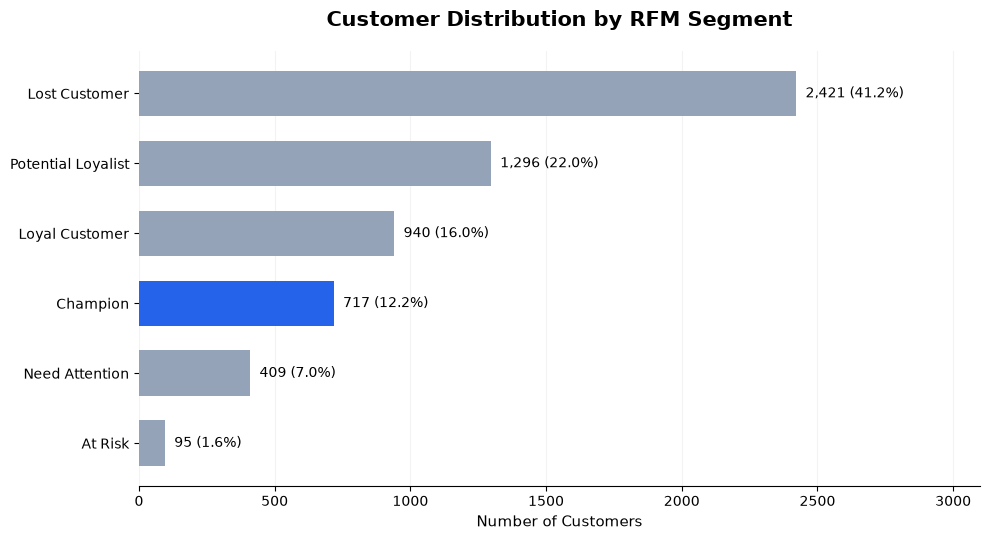

Chart saved: C:\Users\user\OneDrive\Documents\ecommerce-customer_sales-analysis-updated\ecommerce--customer-sales-analysis\outputs\figures\rfm_customer_segment_distribution.png


In [32]:
# RFM-04-08-01 | Customer Segment Distribution

import matplotlib.pyplot as plt
from pathlib import Path

# Prepare visualization data
customer_plot = (
    segment_summary
    .sort_values("Customers", ascending=True)
    .copy()
)

# Create chart
fig, ax = plt.subplots(figsize=(10, 5.5))

colors = [
    "#94A3B8" if segment != "Champion" else "#2563EB"
    for segment in customer_plot["Segment"]
]

bars = ax.barh(
    customer_plot["Segment"],
    customer_plot["Customers"],
    color=colors,
    height=0.65
)

# Add customer count and share labels
for bar, (_, row) in zip(bars, customer_plot.iterrows()):
    ax.text(
        bar.get_width() + 35,
        bar.get_y() + bar.get_height() / 2,
        f'{int(row["Customers"]):,} ({row["Customer_Share_Pct"]:.1f}%)',
        va="center",
        fontsize=10
    )

# Chart formatting
ax.set_title(
    "Customer Distribution by RFM Segment",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Number of Customers", fontsize=11)
ax.set_ylabel("")

ax.set_xlim(0, customer_plot["Customers"].max() * 1.28)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()

# Save chart
output_dir = Path("../outputs/figures")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "rfm_customer_segment_distribution.png"

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Chart saved: {output_path.resolve()}")

### RFM-04-08-02 | Revenue Contribution by Segment

세그먼트별 누적 매출과 전체 RFM 매출 대비 기여도를
시각화하여 핵심 매출 고객군을 파악한다.

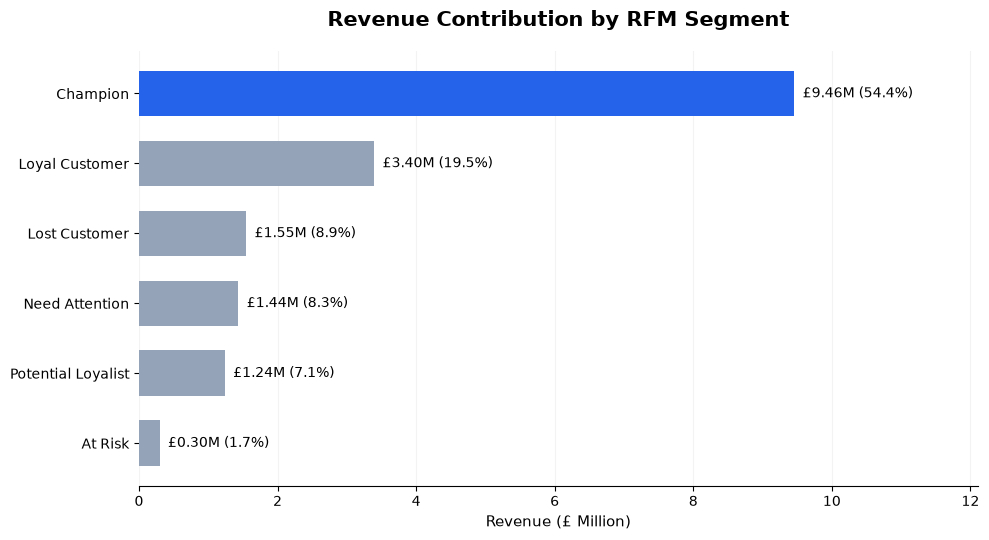

Chart saved: C:\Users\user\OneDrive\Documents\ecommerce-customer_sales-analysis-updated\ecommerce--customer-sales-analysis\outputs\figures\rfm_revenue_contribution_by_segment.png


In [34]:
# RFM-04-08-02 | Revenue Contribution by Segment

# Prepare revenue data
revenue_plot = (
    segment_summary
    .sort_values("Revenue", ascending=True)
    .copy()
)

fig, ax = plt.subplots(figsize=(10, 5.5))

colors = [
    "#2563EB" if segment == "Champion" else "#94A3B8"
    for segment in revenue_plot["Segment"]
]

bars = ax.barh(
    revenue_plot["Segment"],
    revenue_plot["Revenue"] / 1_000_000,
    color=colors,
    height=0.65
)

# Add revenue and share labels
for bar, (_, row) in zip(bars, revenue_plot.iterrows()):
    ax.text(
        bar.get_width() + 0.12,
        bar.get_y() + bar.get_height() / 2,
        f'£{row["Revenue"] / 1_000_000:.2f}M '
        f'({row["Revenue_Share_Pct"]:.1f}%)',
        va="center",
        fontsize=10
    )

ax.set_title(
    "Revenue Contribution by RFM Segment",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Revenue (£ Million)", fontsize=11)
ax.set_ylabel("")

ax.set_xlim(
    0,
    (revenue_plot["Revenue"].max() / 1_000_000) * 1.28
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()

# Save chart using the output_dir defined in RFM-04-08-01
output_path = output_dir / "rfm_revenue_contribution_by_segment.png"

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Chart saved: {output_path.resolve()}")

### RFM-04-08-03 | Visualization Interpretation

**1. Customer Distribution**

- Lost Customer는 2,421명(41.2%)으로 가장 큰 고객 그룹이다.
- Potential Loyalist는 1,296명(22.0%)으로 두 번째로 큰 그룹이다.
- Champion은 717명(12.2%)으로 전체 고객 중 상대적으로 작은 비중을 차지한다.

**2. Revenue Contribution**

- Champion은 전체 고객의 12.2%이지만, RFM 고객 매출의 54.4%를 차지한다.
- Loyal Customer는 고객의 16.0%, 매출의 19.5%를 차지한다.
- Champion과 Loyal Customer를 합하면 고객의 28.19%가 매출의 73.98%를 기여한다.
- Lost Customer는 고객의 41.2%이지만 매출 기여도는 8.9%에 불과하다.

**3. Key Business Insights**

| Finding | Business Implication |
|---|---|
| High Revenue Concentration | Champion 및 Loyal Customer 유지 전략 우선 검토 |
| Large Low-Activity Segment | Lost Customer의 재활성화 대상 선별 필요 |
| Growth Potential | Potential Loyalist의 반복 구매 및 구매 금액 확대 기회 검토 |
| Valuable Inactive Customers | Need Attention 및 At Risk 고객의 과거 구매 가치에 따른 선별적 재활성화 |

**4. Visualization Quality**

- 고객 수와 매출액을 각각 독립적인 수평 막대그래프로 표현하였다.
- 두 차트 모두 Champion을 동일한 색상으로 강조하여 시각적 일관성을 유지하였다.
- 고객 수·비중 및 매출액·비중을 데이터 레이블로 표시하였다.
- 차트를 PNG 형식으로 저장하여 Notebook, GitHub README 및 PPT에 재사용할 수 있도록 구성하였다.

**Key Insight**

RFM 고객 분석에서는 고객 수와 매출 기여도 사이에 뚜렷한 차이가 확인되었다. 따라서 단순한 고객 규모보다는 고객 가치와 구매 활동을 함께 고려하여 마케팅 자원을 배분할 필요가 있다.

**Limitations**

- 본 시각화는 과거 누적 구매 이력에 기반한 분석 결과이다.
- 세그먼트별 매출 기여도는 미래 구매 가능성이나 캠페인 성과를 직접 의미하지 않는다.
- 고객 세분화 기준과 마케팅 전략의 효과는 후속 분석을 통해 추가 검증할 필요가 있다.

## RFM-04-09 | Final Notebook Quality Assurance

### RFM-04-09-01 | Execution Validation

최종 RFM Notebook의 재현성(Reproducibility)을 확인하기 위해 전체 코드의 실행 순서와 의존성을 검증한다.

**Validation Criteria**

- 모든 코드 셀이 처음부터 끝까지 오류 없이 실행되는가?
- 앞선 셀에서 생성하지 않은 변수를 참조하는 코드가 없는가?
- RFM Scoring 및 Customer Segmentation이 최종 4분위 기준을 사용하는가?
- 고객 수, 매출 및 시각화 결과가 기존 검증 결과와 일치하는가?
- 차트 이미지가 지정된 경로에 정상적으로 저장되는가?

In [ ]:
import pandas as pd

# 날짜 형식 확인
sales_df["InvoiceDate"] = pd.to_datetime(
    sales_df["InvoiceDate"]
)

# 분석 기준일: 마지막 거래일 다음 날
snapshot_date = (
    sales_df["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

# 고객별 RFM 집계
rfm = (
    sales_df
    .dropna(subset=["Customer ID"])
    .groupby("Customer ID")
    .agg(
        Recency=(
            "InvoiceDate",
            lambda x: (snapshot_date - x.max()).days
        ),
        Frequency=("Invoice", "nunique"),
        Monetary=("Sales", "sum")
    )
    .reset_index()
)

rfm.head()

In [ ]:
# Revenue by customer segment 

sales_segment = sales_df.merge(
    rfm[["Customer ID", "Segment"]],
    on = "Customer ID",
    how="left"
)

sales_segment.head()


In [ ]:
# Recency: 낮을수록 좋은 고객
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    q=4,
    labels=[4, 3, 2, 1]
).astype(int)

# Frequency: 높을수록 좋은 고객
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    q=4,
    labels=[1, 2, 3, 4]
).astype(int)

# Monetary: 높을수록 좋은 고객
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    q=4,
    labels=[1, 2, 3, 4]
).astype(int)

In [ ]:
rfm["RF_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
)

In [ ]:
def assign_customer_segment(row):
    r = row["R_Score"]
    f = row["F_Score"]

    if r == 4 and f == 4:
        return "Champion"

    elif r >= 3 and f >= 3:
        return "Loyal Customer"

    elif r >= 3 and f <= 2:
        return "Potential Loyalist"

    elif r == 2 and f >= 3:
        return "Need Attention"

    elif r == 1 and f >= 3:
        return "At Risk"

    elif r == 1 and f <= 2:
        return "Lost Customer"

    else:
        return "Others"

In [ ]:
rfm["Customer Segment"] = rfm.apply(
    assign_customer_segment,
    axis=1
)

In [ ]:
print(rfm.columns.tolist())

In [ ]:
revenue_plot = (
    segment_summary
    .sort_values("Revenue", ascending=True)
    .copy()
)

fig, ax = plt.subplots(figsize=(7.5, 5))

bars = ax.barh(
    revenue_plot["Customer Segment"],
    revenue_plot["Revenue"],
    color="#34A853",
    height=0.62
)

# 차트 제목 제거 (README의 제목을 사용)

ax.set_xlabel("Revenue (Millions of £)", fontsize=11)
ax.set_ylabel("")

ax.grid(
    axis="x",
    alpha=0.22
)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

max_revenue = revenue_plot["Revenue"].max()

# 데이터 레이블
for bar in bars:
    value = bar.get_width()

    ax.text(
        value + max_revenue * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"£{value / 1_000_000:.1f}M",
        va="center",
        fontsize=9,
        color="#444444"
    )

# x축을 백만 파운드 단위로 표시
ticks = ax.get_xticks()

ax.set_xticks(ticks)
ax.set_xticklabels([
    f"{tick / 1_000_000:.0f}"
    for tick in ticks
])

ax.set_xlim(0, max_revenue * 1.18)

plt.tight_layout()

plt.savefig(
    "../images/rfm_revenue_by_segment.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [ ]:

# Slide 07 - Customer Revenue Pareto Analysis

import pandas as pd

# 1. Sort customers by revenue
customer_pareto = (
    rfm[["Sales"]]
    .sort_values("Sales", ascending=False)
    .reset_index()
)

# 2. Calculate cumulative revenue
customer_pareto["Cumulative Revenue"] = (
    customer_pareto["Sales"].cumsum()
)

customer_pareto["Cumulative Percentage"] = (
    customer_pareto["Cumulative Revenue"]
    / customer_pareto["Sales"].sum() * 100
)

# 3. Identify customers needed to reach 80% revenue
cutoff = customer_pareto[
    customer_pareto["Cumulative Percentage"] >= 80
].index[0]

top_customer_count = cutoff + 1
total_customers = len(customer_pareto)

top_customer_share = (
    top_customer_count / total_customers * 100
)

top_revenue_share = (
    customer_pareto.iloc[:top_customer_count]["Sales"].sum()
    / customer_pareto["Sales"].sum() * 100
)

# 4. Calculate customer revenue
rfm_total_revenue = customer_pareto["Sales"].sum()

print("=== CUSTOMER REVENUE PARETO ===")
print(f"Total Customers: {total_customers:,}")
print(f"Customer Revenue: £{rfm_total_revenue:,.2f}")
print(f"Customers for 80% Revenue: {top_customer_count:,}")
print(f"Customer Share: {top_customer_share:.2f}%")
print(f"Revenue Share: {top_revenue_share:.2f}%")

# 5. Show top customers
print("\n=== TOP 5 CUSTOMERS ===")
display(customer_pareto.head(5))


In [ ]:
# Restore RFM analysis columns
rfm = rfm.rename(columns={
    "InvoiceDate": "Recency",
    "Invoice": "Frequency",
    "Sales": "Monetary"
})

# Validate restored RFM data
print("=== RFM RESTORED ===")
print("Shape:", rfm.shape)
print("Columns:", rfm.columns.tolist())
print("Unique Customers:", rfm.index.nunique())

display(rfm.head())

In [ ]:
# STEP 2: RFM Scoring (4 Quartiles)

# Recency: Lower is better
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    q=4,
    labels=[4, 3, 2, 1]
).astype(int)

# Frequency: Higher is better
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    q=4,
    labels=[1, 2, 3, 4]
).astype(int)

# Monetary: Higher is better
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    q=4,
    labels=[1, 2, 3, 4]
).astype(int)

# Combine R and F scores
rfm["RF_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
)

# Validation
print("=== RFM SCORING VALIDATION ===")
print("Shape:", rfm.shape)

print("\nScore Ranges:")
print(
    rfm[["R_Score", "F_Score", "M_Score"]]
    .agg(["min", "max"])
)

display(rfm.head())

In [ ]:
# STEP 3: Customer Segmentation

def assign_customer_segment(row):
    r = row["R_Score"]
    f = row["F_Score"]

    if r == 4 and f == 4:
        return "Champion"

    elif r >= 3 and f >= 3:
        return "Loyal Customer"

    elif r >= 3 and f <= 2:
        return "Potential Loyalist"

    elif r == 2 and f >= 3:
        return "Need Attention"

    elif r == 1 and f >= 3:
        return "At Risk"

    elif r == 1 and f <= 2:
        return "Lost Customer"

    else:
        return "Others"


# Apply segmentation
rfm["Customer Segment"] = rfm.apply(
    assign_customer_segment,
    axis=1
)

# Validation
print("=== CUSTOMER SEGMENTATION ===")

print(
    rfm["Customer Segment"]
    .value_counts()
)

print("\nTotal Customers:", len(rfm))
print("Assigned Customers:",
      rfm["Customer Segment"].notna().sum())

display(rfm.head())

In [ ]:
# STEP 4: Segment Revenue Analysis

segment_summary = (
    rfm.groupby("Customer Segment")
       .agg(
           Customers=("Monetary", "size"),
           Revenue=("Monetary", "sum"),
           Avg_Revenue_Per_Customer=("Monetary", "mean")
       )
       .reset_index()
)

# Calculate shares
segment_summary["Customer_Share"] = (
    segment_summary["Customers"]
    / segment_summary["Customers"].sum() * 100
)

segment_summary["Revenue_Share"] = (
    segment_summary["Revenue"]
    / segment_summary["Revenue"].sum() * 100
)

# Sort by revenue
segment_summary = segment_summary.sort_values(
    "Revenue", ascending=False
).reset_index(drop=True)

# Validation
print("=== FINAL SEGMENT SUMMARY ===")
print("Total Customers:", segment_summary["Customers"].sum())
print("Total Revenue:", round(segment_summary["Revenue"].sum(), 2))
print("Customer Share:", round(segment_summary["Customer_Share"].sum(), 2))
print("Revenue Share:", round(segment_summary["Revenue_Share"].sum(), 2))

display(segment_summary.round(2))